In [133]:
import numpy as np
import pandas as pd
import sqlite3  # swap for your actual connection (SQLAlchemy engine, etc.)

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import re

from sklearn.model_selection import TimeSeriesSplit
from sklearn.dummy import DummyClassifier

conn = sqlite3.connect('../data/finance.db')

In [129]:
pd.read_sql(
    "SELECT interval, source, COUNT(*) AS n, COUNT(DISTINCT ticker) AS tickers, "
    "MIN(datetime) AS first, MAX(datetime) AS last "
    "FROM price_history GROUP BY interval, source",
    conn,
)

,interval,source,n,tickers,first,last
0,15m,yfinance,313423,503,2026-09-10 09:30:00-0400,2026-10-19 15:45:00-0400
1,1d,yfinance,2954808,503,2000-01-03,2026-10-19
2,5m,yfinance,1716,1,2026-09-10 09:30:00-0400,2026-10-09 15:55:00-0400


In [83]:
# Top 10 stock tickers categorized by GICS sectors
sector_tickers = {
    "Technology": [
        "NVDA", "AAPL", "MSFT", "AVGO", "ORCL", 
        "AMD", "QCOM", "INTC", "CRM", "ADBE"
    ],
    "Communication_Services": [
        "GOOGL", "META", "NFLX", "TMUS", "DIS", 
        "VZ", "T", "CMCSA", "CHTR", "WBD"
    ],
    "Consumer_Discretionary": [
        "AMZN", "TSLA", "HD", "MCD", "NKE", 
        "BKNG", "LOW", "TJX", "SBUX", "CMG"
    ],
    "Financials": [
        "BRK-B", "JPM", "V", "MA", "BAC", 
        "WFC", "GS", "MS", "BLK", "C"
    ],
    "Health_Care": [
        "LLY", "JNJ", "UNH", "ABBV", "MRK", 
        "TMO", "ABT", "PFE", "DHR", "AMGN"
    ],
    "Consumer_Staples": [
        "WMT", "COST", "PG", "KO", "PEP", 
        "PM", "MDLZ", "MO", "CL", "TGT"
    ],
    "Industrials": [
        "GE", "CAT", "RTX", "HON", "UNP", 
        "BA", "LMT", "UPS", "FDX", "GD"
    ],
    "Energy": [
        "XOM", "CVX", "COP", "MPC", "SLB", 
        "EOG", "PSX", "VLO", "OXY"
    ],
    "Materials": [
        "LIN", "SHW", "FCX", "NEM", "APD", 
        "NUE", "DOW", "ECL", "DD", "PPG"
    ],
    "Utilities": [
        "NEE", "SO", "DUK", "CEG", "SRE", 
        "AEP", "D", "EXC", "XEL", "PCG"
    ],
    "Real_Estate": [
        "PLD", "AMT", "EQIX", "CCI", "PSA", 
        "DLR", "O", "WELL", "SPG", "VICI"
    ]
}

all_tickers = [ticker for tickers in sector_tickers.values() for ticker in tickers]

In [84]:
def parse_lookback(period):
    """Convert a period spec into a pandas DateOffset.

    Parameters
    ----------
    period : str or pandas.DateOffset
        Either a string made of an integer and a unit (``"y"`` for years,
        ``"m"`` for months, ``"w"`` for weeks, ``"d"`` for days), such as
        ``"2y"`` or ``"18m"``, or a ready-made ``pandas.DateOffset``
        (for example ``pd.DateOffset(years=1, months=6)``).

    Returns
    -------
    pandas.DateOffset
        The equivalent offset.

    Raises
    ------
    ValueError
        If a string does not match the expected format.
    """
    

    
    if isinstance(period, pd.DateOffset):
        return period
    match = re.fullmatch(r"\s*(\d+)\s*([ymwd])\s*", str(period).lower())
    if not match:
        raise ValueError(f"Can't parse lookback {period!r}; use e.g. '2y', '6m', '90d'.")
    n, unit = int(match.group(1)), match.group(2)
    keyword = {"y": "years", "m": "months", "w": "weeks", "d": "days"}[unit]
    return pd.DateOffset(**{keyword: n})

In [85]:
def regular_hours_only(prices, tz="America/New_York", start="09:30", end="16:00"):
    """Keep only bars that start within the regular trading session.

    Parameters
    ----------
    prices : pandas.DataFrame
        Output of ``load_prices`` for an intraday interval, with a
        timezone-naive ``date`` column holding UTC timestamps.
    tz : str, optional
        Exchange time zone. Default is ``"America/New_York"``.
    start : str, optional
        Session open as ``"HH:MM"`` in exchange time. Default is
        ``"09:30"``.
    end : str, optional
        Session close as ``"HH:MM"`` in exchange time. Bars starting at
        or after this time are dropped. Default is ``"16:00"``.

    Returns
    -------
    pandas.DataFrame
        Rows whose bar start time falls inside the session, or the input
        unchanged if it contains only daily-or-longer bars.
    """
    if (prices["date"] == prices["date"].dt.normalize()).all():
        return prices
    
    local = prices["date"].dt.tz_localize("UTC").dt.tz_convert(tz)
    minutes = local.dt.hour * 60 + local.dt.minute

    def to_minutes(hhmm):
        h, m = map(int, hhmm.split(":"))
        return h * 60 + m

    mask = (minutes >= to_minutes(start)) & (minutes < to_minutes(end))
    return prices[mask].reset_index(drop=True)

In [139]:
def _features_one_ticker(df, horizon):
    """Compute features and forward return for a single ticker.

    Parameters
    ----------
    df : pandas.DataFrame
        Price bars for one ticker with columns ``date``, ``close``,
        ``volume`` and optionally ``high`` and ``low``, sorted by date.
    horizon : int
        Number of bars ahead for the forward return.

    Returns
    -------
    pandas.DataFrame
        Features and ``fwd_ret``, indexed by date.
    """
    df = df.set_index("date")
    ret = df["close"].pct_change()
    out = pd.DataFrame(index=df.index)
    out["ret_1"] = ret
    out["ret_5"] = df["close"].pct_change(5)
    out["vol_20"] = ret.rolling(20).std()
    if {"high", "low"}.issubset(df.columns):
        out["range"] = (df["high"] - df["low"]) / df["close"]
    vol_mean = df["volume"].rolling(20).mean()
    vol_std = df["volume"].rolling(20).std()
    out["vol_z"] = (df["volume"] - vol_mean) / vol_std
    out["ma_gap"] = df["close"] / df["close"].rolling(20).mean() - 1
    out["fwd_ret"] = df["close"].shift(-horizon) / df["close"] - 1
    return out

In [135]:
def build_panel(prices, horizon=5, relative=True):
    """Build a pooled feature table across all tickers.

    Parameters
    ----------
    prices : pandas.DataFrame
        Output of ``load_prices``.
    horizon : int, optional
        Number of bars ahead for the label, by default 5.
    relative : bool, optional
        If True, the target is 1 when a ticker's forward return beats the
        median forward return of all tickers on that date. If False, the
        target is 1 when the forward return is positive. By default True.

    Returns
    -------
    pandas.DataFrame
        Indexed by datetime, with a ``ticker`` column, the features, and a
        binary ``target`` column. Rows without a full feature window or
        forward return are dropped.
    """
    parts = []
    for ticker, grp in prices.groupby("ticker"):
        feats = _features_one_ticker(grp, horizon)
        feats["ticker"] = ticker
        parts.append(feats)
    panel = pd.concat(parts).dropna()

    if relative:
        median = panel.groupby(level=0)["fwd_ret"].transform("median")
        panel["target"] = (panel["fwd_ret"] > median).astype(int)
    else:
        panel["target"] = (panel["fwd_ret"] > 0).astype(int)
    return panel.sort_index()

In [136]:
def walk_forward(panel, horizon=5, n_splits=5):
    """Run walk-forward evaluation on a pooled panel, splitting by date.

    Parameters
    ----------
    panel : pandas.DataFrame
        Output of ``build_panel``.
    horizon : int, optional
        Gap, in dates, left between train and test, by default 5.
    n_splits : int, optional
        Number of walk-forward folds, by default 5.

    Returns
    -------
    pandas.DataFrame
        Per-fold balanced accuracy and AUC for the model and a baseline.
    """
    features = [c for c in panel.columns if c not in ("ticker", "fwd_ret", "target")]
    dates = np.sort(panel.index.unique())
    rows = []
    for train_d, test_d in TimeSeriesSplit(n_splits=n_splits, gap=horizon).split(dates):
        train = panel[panel.index.isin(dates[train_d])]
        test = panel[panel.index.isin(dates[test_d])]
        model = GradientBoostingClassifier().fit(train[features], train["target"])
        base = DummyClassifier(strategy="prior").fit(train[features], train["target"])
        rows.append({
            "model_bal_acc": balanced_accuracy_score(test["target"], model.predict(test[features])),
            "model_auc": roc_auc_score(test["target"], model.predict_proba(test[features])[:, 1]),
            "base_bal_acc": balanced_accuracy_score(test["target"], base.predict(test[features])),
            "base_auc": roc_auc_score(test["target"], base.predict_proba(test[features])[:, 1]),
        })
    return pd.DataFrame(rows)

In [137]:
def load_prices(conn, interval="1d", period=None, tickers=None, source=None):
    """Load price history for one bar interval from the database.

    Parameters
    ----------
    conn : sqlite3.Connection
        Open connection to the project database.
    interval : str, optional
        Bar interval to select, matching the ``interval`` column.
        Default is ``"1d"``.
    period : str, pandas.DateOffset, or None, optional
        If given, keep only the most recent span of data, measured back
        from the latest date in the table. See ``parse_lookback`` for
        accepted formats. Default is None (all history).
    tickers : list of str
        Tickers to keep. Case-insensitive.
    source : str or None, optional
        Data source to select, matching the ``source`` column. If None,
        no source filter is applied, so make sure only one source has
        data for each ticker and date.

    Returns
    -------
    pandas.DataFrame
        Columns ``ticker``, ``date``, ``close``, ``volume``, sorted by
        ticker and date.
    """
    
    query = (
        "SELECT ticker, datetime, Close AS close, Volume AS volume "
        "FROM price_history WHERE interval = ?"
    )
    params = [interval]
    if source is not None:
        query += " AND source = ?"
        params.append(source)
    
    df = pd.read_sql(query, conn, params=params)
    dt = pd.to_datetime(df["datetime"], utc=True).dt.tz_localize(None)
    intraday = interval.lower().endswith(("m", "h")) 
    df["date"] = dt if intraday else dt.dt.normalize()
    df = df.drop(columns="datetime")
    
    if period is not None:
        cutoff = df["date"].max() - parse_lookback(period)
        df = df[df["date"] >= cutoff]
    
    if tickers is not None:
        wanted = [t.upper() for t in tickers]
        missing = sorted(set(wanted) - set(df["ticker"].str.upper()))
        if missing:
            print(f"Not in database, skipped: {missing}")
        mask = df["ticker"].str.upper().isin(wanted)
        df = df[mask].reset_index(drop=True)

    dupes = df.duplicated(["ticker", "date"]).sum()
    if dupes:
        raise ValueError(f"{dupes} duplicate ticker/date rows; filter by source.")

    return df.sort_values(["ticker", "date"]).reset_index(drop=True)[
        ["ticker", "date", "close", "volume"]
    ]


prices = load_prices(conn, interval="1d", period="6m", source=None)  # adjust values

# prices = regular_hours_only(load_prices(conn, interval="15m", period="6m"))

prices.head()

,ticker,date,close,volume
0,A,2026-04-20,120.548065,1252200
1,A,2026-04-21,121.674210,1800100
2,A,2026-04-22,120.059731,1800900
3,A,2026-04-23,114.030334,2620100
4,A,2026-04-24,115.156487,1496100


In [140]:
panel = build_panel(prices, horizon=5, relative=True)
print(walk_forward(panel, horizon=5))

   model_bal_acc  model_auc  base_bal_acc  base_auc
0       0.519800   0.526750           0.5       0.5
1       0.506812   0.508933           0.5       0.5
2       0.503777   0.506764           0.5       0.5
3       0.500743   0.504619           0.5       0.5
4       0.464372   0.465109           0.5       0.5


In [126]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


def cluster_stocks(profiles, n_clusters=4):
    """Group tickers into clusters based on their profile statistics.

    Parameters
    ----------
    profiles : pandas.DataFrame
        Output of ``stock_profiles``.
    n_clusters : int, optional
        Number of groups to find. Default is 4.

    Returns
    -------
    pandas.Series
        Cluster label for each ticker, indexed by ticker.
    """
    scaled = StandardScaler().fit_transform(profiles)  # put columns on equal footing
    km = KMeans(n_clusters=n_clusters, n_init=10, random_state=0)
    return pd.Series(km.fit_predict(scaled), index=profiles.index, name="cluster")


profiles["cluster"] = cluster_stocks(profiles, n_clusters=8)
profiles.groupby("cluster").agg(["mean", "count"]).round(4)

avg_return       volatility          beta       vol_annual      
              mean count       mean count    mean count       mean count
cluster                                                                 
0           0.0046    18     0.0553    18  1.1983    18     0.8776    18
1           0.0011   129     0.0192   129  0.7560   129     0.3045   129
2          -0.0011    43     0.0350    43  1.5456    43     0.5555    43
3          -0.0000   123     0.0218   123  1.6236   123     0.3467   123
4           0.0187     1     0.1660     1  4.7814     1     2.6350     1
5           0.0012    20     0.0219    20 -0.7892    20     0.3476    20
6          -0.0002   128     0.0145   128  0.5871   128     0.2294   128
7           0.0036    41     0.0346    41  1.1747    41     0.5497    41

In [122]:
def annualize_volatility(vol, bars_per_day=1, days_per_year=252):
    """Convert per-bar volatility to an annualized figure.

    Parameters
    ----------
    vol : float or pandas.Series
        Standard deviation of per-bar returns.
    bars_per_day : int, optional
        Number of bars in one trading day. Default is 26, which matches
        15-minute bars in a regular 6.5-hour session.
    days_per_year : int, optional
        Trading days per year. Default is 252.

    Returns
    -------
    float or pandas.Series
        Volatility scaled by ``sqrt(bars_per_day * days_per_year)``.
    """
    return vol * (bars_per_day * days_per_year) ** 0.5


profiles["vol_annual"] = annualize_volatility(profiles["volatility"])

In [127]:
mask = profiles.index.isin(all_tickers)   # boolean array, one entry per row
sub_profiles = profiles[mask]

0 ['AMD', 'BE', 'COHR', 'DDOG', 'DELL', 'FLEX', 'GLW', 'HPE', 'INTC', 'LITE']
1 ['AAPL', 'ABBV', 'ABT', 'ADBE', 'ADP', 'ADSK', 'AIZ', 'AJG', 'AME', 'AMGN']
2 ['ALB', 'APP', 'APTV', 'ARE', 'AXON', 'BSX', 'CEG', 'CHTR', 'CIEN', 'COIN']
3 ['ABNB', 'ADI', 'ALGN', 'ALLE', 'AMCR', 'AOS', 'APH', 'APO', 'ARES', 'AVY']
4 ['MRNA']
5 ['ADM', 'APA', 'BG', 'CASY', 'CBOE', 'CF', 'COP', 'CVX', 'DOW', 'DVN']
6 ['ACGL', 'AEE', 'AEP', 'AES', 'AFL', 'AIG', 'ALL', 'AMP', 'AON', 'APD']
7 ['A', 'ACN', 'AKAM', 'AMAT', 'ANET', 'BBY', 'CDW', 'CNC', 'CRL', 'CRM']


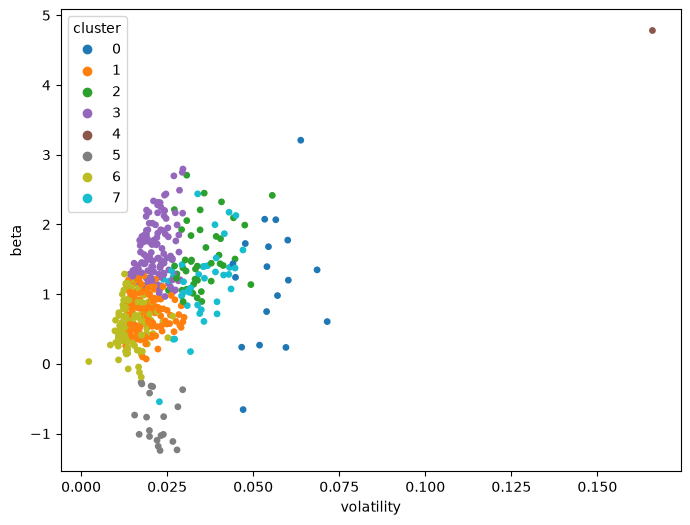

In [128]:
import matplotlib.pyplot as plt

plot_sub = False

fig, ax = plt.subplots(figsize=(8, 6))

if plot_sub:
    scatter = (
        ax.scatter(sub_profiles["volatility"], sub_profiles["beta"], c=sub_profiles["cluster"], cmap="tab10", s=15)
    )
    for c in sorted(sub_profiles["cluster"].unique()):
        print(c, list(sub_profiles[sub_profiles["cluster"] == c].index[:10]))
else:
    scatter = (
    ax.scatter(profiles["volatility"], profiles["beta"], c=profiles["cluster"], cmap="tab10", s=15)
    )
    for c in sorted(profiles["cluster"].unique()):
        print(c, list(profiles[profiles["cluster"] == c].index[:10]))
ax.set_xlabel("volatility")
ax.set_ylabel("beta")
ax.legend(*scatter.legend_elements(), title="cluster")
plt.show()

In [142]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA


def build_return_matrix(prices, min_coverage=0.9):
    """Pivot prices into a date by ticker matrix of daily log returns.

    Parameters
    ----------
    prices : pandas.DataFrame
        Output of ``load_prices`` with columns ``ticker``, ``date``,
        ``close``.
    min_coverage : float, optional
        Minimum fraction of dates a ticker must have a price for, otherwise
        it is dropped. Default is 0.9.

    Returns
    -------
    pandas.DataFrame
        Log returns indexed by date, one column per ticker, with no missing
        values.
    """
    wide = prices.pivot(index="date", columns="ticker", values="close")
    wide = wide.loc[:, wide.notna().mean() >= min_coverage]
    rets = np.log(wide).diff().dropna(how="any")
    return rets


def fit_pca(rets, n_components=10):
    """Fit PCA to standardized returns.

    Parameters
    ----------
    rets : pandas.DataFrame
        Output of ``build_return_matrix``.
    n_components : int, optional
        Number of principal components to keep. Default is 10.

    Returns
    -------
    pca : sklearn.decomposition.PCA
        Fitted PCA object.
    loadings : pandas.DataFrame
        Tickers by component loadings, columns ``PC1``, ``PC2``, and so on.
    """
    n_components = min(n_components, rets.shape[1])
    # Standardize so high-volatility stocks do not dominate the components.
    X = StandardScaler().fit_transform(rets)
    pca = PCA(n_components=n_components).fit(X)
    loadings = pd.DataFrame(
        pca.components_.T,
        index=rets.columns,
        columns=[f"PC{i + 1}" for i in range(n_components)],
    )
    return pca, loadings

def residual_returns(rets, n_remove=1):
    """Remove leading principal components from standardized returns.

    Parameters
    ----------
    rets : pandas.DataFrame
        Output of ``build_return_matrix``.
    n_remove : int, optional
        Number of leading components (the market factor and so on) to
        remove. Default is 1.

    Returns
    -------
    pandas.DataFrame
        Residual returns with the same shape as ``rets``.
    """
    X = StandardScaler().fit_transform(rets)
    pca = PCA(n_components=n_remove).fit(X)
    recon = pca.inverse_transform(pca.transform(X))
    return pd.DataFrame(X - recon, index=rets.index, columns=rets.columns)


def cluster_by_correlation(rets, n_clusters=8):
    """Cluster tickers using correlation distance.

    Parameters
    ----------
    rets : pandas.DataFrame
        Output of ``build_return_matrix``.
    n_clusters : int, optional
        Number of clusters to form. Default is 8.

    Returns
    -------
    pandas.Series
        Cluster label for each ticker, indexed by ticker.
    """
    dist = 1 - rets.corr()
    model = AgglomerativeClustering(
        n_clusters=n_clusters, metric="precomputed", linkage="average"
    )
    labels = model.fit_predict(dist.values)
    return pd.Series(labels, index=dist.index, name="cluster")



prices = load_prices(conn, interval="1d", source="yfinance")
rets = build_return_matrix(prices)

# PCA: fit with all components so the 80% count is real
pca, loadings = fit_pca(rets, n_components=rets.shape[1])
cum = np.cumsum(pca.explained_variance_ratio_)
print("Variance explained (first 10):", pca.explained_variance_ratio_[:10].round(3))
print("Components needed for 80%:", int(np.searchsorted(cum, 0.80)) + 1)

# Clustering: remove the market factor, then Ward linkage
resid = residual_returns(rets, n_remove=1)
model = AgglomerativeClustering(n_clusters=11, linkage="ward")
labels = model.fit_predict(resid.T.values)
clusters = pd.Series(labels, index=resid.columns, name="cluster")

print(clusters.value_counts().sort_index())

sectors = pd.read_sql("SELECT ticker, sector FROM tickers", conn).set_index("ticker")["sector"]
table = pd.crosstab(clusters, sectors.reindex(clusters.index).fillna("Unknown"))
print(table)

Variance explained (first 10): [0.366 0.039 0.026 0.02  0.016 0.012 0.011 0.009 0.008 0.008]
Components needed for 80%: 131
cluster
0     65
1     81
2     61
3     13
4     20
5     17
6     16
7     25
8     16
9     32
10    23
Name: count, dtype: int64
sector   Communication Services  Consumer Discretionary  Consumer Staples  \
cluster                                                                     
0                             2                       0                 6   
1                             3                      15                 1   
2                             3                       4                 0   
3                             0                       0                13   
4                             0                      13                 6   
5                             0                       0                 0   
6                             0                       0                 0   
7                             0                   

In [143]:
def odd_ones_out(clusters, sectors):
    """List tickers whose sector differs from their cluster's majority sector.

    Parameters
    ----------
    clusters : pandas.Series
        Cluster label for each ticker, indexed by ticker.
    sectors : pandas.Series
        Sector label for each ticker, indexed by ticker.

    Returns
    -------
    pandas.DataFrame
        Columns ``cluster``, ``sector`` and ``cluster_majority`` for each
        ticker that does not match its cluster's most common sector.
    """
    df = pd.DataFrame({
        "cluster": clusters,
        "sector": sectors.reindex(clusters.index).fillna("Unknown"),
    })
    majority = df.groupby("cluster")["sector"].agg(lambda s: s.mode().iloc[0])
    df["cluster_majority"] = df["cluster"].map(majority)
    return df[df["sector"] != df["cluster_majority"]].sort_values(["cluster", "sector"])


print(odd_ones_out(clusters, sectors))

        cluster                  sector cluster_majority
ticker                                                  
T             0  Communication Services      Health Care
VZ            0  Communication Services      Health Care
BF-B          0        Consumer Staples      Health Care
MNST          0        Consumer Staples      Health Care
MO            0        Consumer Staples      Health Care
...         ...                     ...              ...
MOS          10               Materials           Energy
NEM          10               Materials           Energy
NUE          10               Materials           Energy
STLD         10               Materials           Energy
AES          10               Utilities           Energy

[98 rows x 3 columns]


In [144]:
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 200):
    print(odd_ones_out(clusters, sectors))

        cluster                  sector        cluster_majority
ticker                                                         
T             0  Communication Services             Health Care
VZ            0  Communication Services             Health Care
BF-B          0        Consumer Staples             Health Care
MNST          0        Consumer Staples             Health Care
MO            0        Consumer Staples             Health Care
STZ           0        Consumer Staples             Health Care
SYY           0        Consumer Staples             Health Care
TSN           0        Consumer Staples             Health Care
GD            0             Industrials             Health Care
LHX           0             Industrials             Health Care
LMT           0             Industrials             Health Care
NOC           0             Industrials             Health Care
RSG           0             Industrials             Health Care
WM            0             Industrials 